In [1]:
!pip install face-recognition

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/100.1 MB ? eta -:--:--
     ---------------------------------------- 0.3/100.1 MB ? eta -:--:--
     ---------------------------------------- 1.0/100.1 MB 4.6 MB/s eta 0:00:22
      --------------------------------------- 1.8/100.1 MB 4.8 MB/s eta 0:00:21
     - -------------------------------------- 3.1/100.1 MB 4.6 MB/s eta 0:00:22
     - -------------------------------------- 3.4/100.1 MB 4.4 MB/s eta 0:00:23
     - -------------------------------------- 3.7/100.1 MB 3.6 MB/s eta 0:00:27
     - -------------------------------------- 3.9/100.1 MB 3.2 MB/s eta 0:00:31
     - -------------------------------------- 4.2/100.1 MB 3.0 MB/s eta 0:00:33
     - -------------------------------------- 4.5/100.1 MB 2.7 MB/s eta 0:00:36
     - -------------------------------------- 4.7/100.1 MB 2.6 MB/s eta 0:00:37
     -- ------------------------------------- 5.2/100.1 

  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> [47 lines of output]
      C:\Users\salah\AppData\Local\Temp\pip-install-m1x0d9nc\dlib_085d2963db264c2d9edcd25500117c39\setup.py:234: SyntaxWarning: invalid escape sequence '\('
        major = re.findall("set\(CPACK_PACKAGE_VERSION_MAJOR.*\"(.*)\"", open(cmake_file).read())[0]
      C:\Users\salah\AppData\Local\Temp\pip-install-m1x0d9nc\dlib_085d2963db264c2d9edcd25500117c39\setup.py:235: SyntaxWarning: invalid escape sequence '\('
        minor = re.findall("set\(CPACK_PACKAGE_VERSION_MINOR.*\"(.*)\"", open(cmake_file).read())[0]
      C:\Users\salah\AppData\Local\Temp\pip-install-m1x0d9nc\dlib_085d2963db264c2d9edcd25500117c39\setup.py:236: SyntaxWarning: invalid escape sequence '\('
        patch = re.findall("set\(CPACK_PACKAGE_VERSION_PATCH.*\"(.*)\"", open(cmake_file).read())[0]
      running bdist_wheel
      running build
      running build_ext
      
      

In [9]:
pip install face_recognition


  Using cached face_recognition-1.3.0-py2.py3-none-any.whl.metadata (21 kB)
  Using cached face_recognition_models-0.3.0-py2.py3-none-any.whl
  Using cached dlib-19.24.6.tar.gz (3.4 MB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
Using cached face_recognition-1.3.0-py2.py3-none-any.whl (15 kB)
  Created wheel for dlib: filename=dlib-19.24.6-cp312-cp312-win_amd64.whl size=2893203 sha256=f4955335a5fefef14a19c6b9e5780e00d100b44ca120c558db6d8f905ef6cabe
  Stored in directory: c:\users\salah\appdata\local\pip\cache\wheels\8d\16\b2\d2df2ea5d9430e80343c7b696e9588e5cc98b0d903d434d768
Successfully built dlib
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
pip install cmake

   ---------------------------------------- 0.0/36.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.4 MB ? eta -:--:--
    --------------------------------------- 0.5/36.4 MB 3.4 MB/s eta 0:00:11
   - -------------------------------------- 1.0/36.4 MB 1.9 MB/s eta 0:00:19
   -- ------------------------------------- 2.4/36.4 MB 3.3 MB/s eta 0:00:11
   -- ------------------------------------- 2.4/36.4 MB 3.3 MB/s eta 0:00:11
   -- ------------------------------------- 2.6/36.4 MB 2.2 MB/s eta 0:00:16
   -- ------------------------------------- 2.6/36.4 MB 2.2 MB/s eta 0:00:16
   --- ------------------------------------ 2.9/36.4 MB 2.0 MB/s eta 0:00:17
   --- ------------------------------------ 3.4/36.4 MB 1.8 MB/s eta 0:00:18
   ---- ----------------------------------- 3.7/36.4 MB 1.8 MB/s eta 0:00:19
   ---- ----------------------------------- 3.9/36.4 MB 1.8 MB/s eta 0:00:19
   ---- ----------------------------------- 4.2/36.4 MB 1.7 MB/s eta 0:00:19
   ---- -----


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
cmake --version


NameError: name 'cmake' is not defined

In [10]:
import face_recognition
import glob
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
import os
from tqdm import tqdm
import seaborn as sns
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from face_recognition.face_recognition_cli import image_files_in_folder
import cv2
import pandas as pd

In [11]:
df = pd.read_csv('D:\\Face recognition\\Dataset.csv')
df.head()

,id,label
0,Robert Downey Jr_87.jpg,Robert Downey Jr
1,Lisa Kudrow_64.jpg,Lisa Kudrow
2,Ellen Degeneres_34.jpg,Ellen Degeneres
3,Billie Eilish_3.jpg,Billie Eilish
4,Hrithik Roshan_35.jpg,Hrithik Roshan


In [12]:
df.shape

(2562, 2)

In [13]:
df.label.value_counts().to_frame()

,count
label,
Brad Pitt,120
Vijay Deverakonda,115
Robert Downey Jr,113
Hugh Jackman,112
Jessica Alba,108
Henry Cavill,106
Natalie Portman,105
Priyanka Chopra,102
Hrithik Roshan,101


In [14]:
names=df.label.value_counts()

C:\Users\salah\AppData\Local\Temp\ipykernel_20296\1855872658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=names.index, x=names.values, palette='viridis')


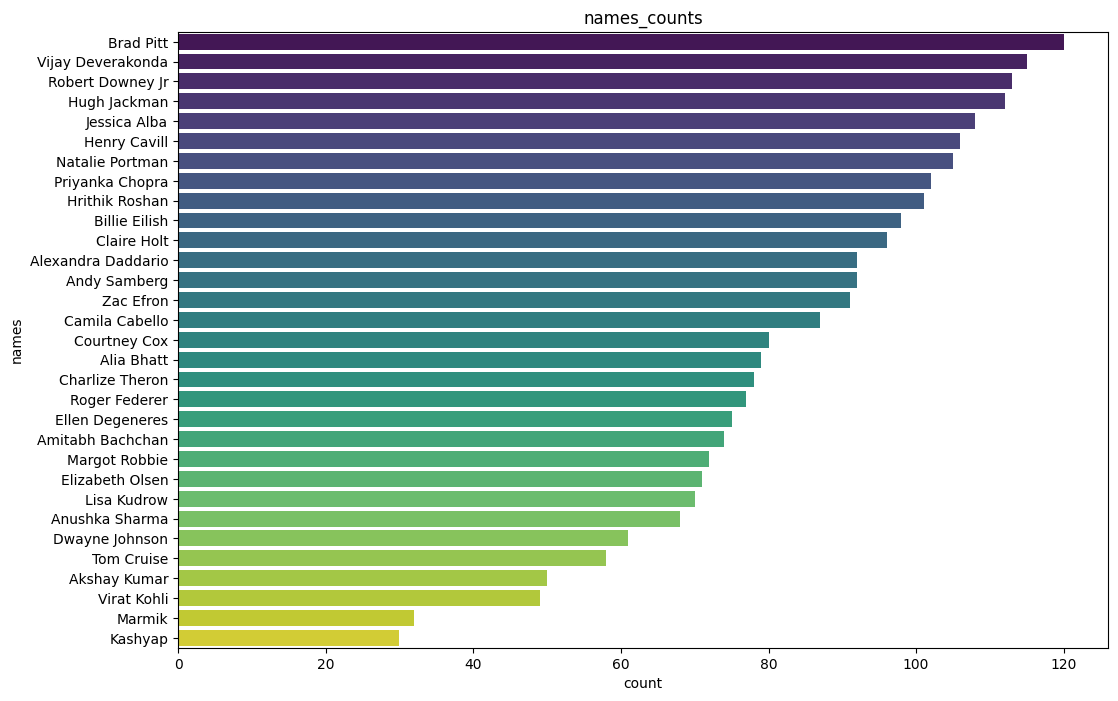

In [15]:
plt.figure(figsize=(12, 8))
sns.barplot(y=names.index, x=names.values, palette='viridis')
plt.title('names_counts')
plt.ylabel('names')  # Now this will represent the y-axis
plt.xlabel('count')   # Now this will represent the x-axis
plt.show()

In [16]:
dirpath='D:\\Face recognition\\Original Images\\Original Images'
def create_dataset(dirpath):
  images=[]
  labels=[]
  images=list(Path(dirpath).glob('**/*.jpg'))
  for i in range(len(images)):
      label= os.path.split(os.path.split(images[i])[0])[1]
      labels.append(label)
  print(len(set(labels)))
  print(len(os.listdir(dirpath)))
  return images,labels
images,labels=create_dataset(dirpath)

31
31


In [17]:
subdirs=dict()
for subdir in os.listdir(dirpath):
   subdirs[subdir]=len(os.listdir(os.path.join(dirpath,subdir)))
print(subdirs)

{'Akshay Kumar': 50, 'Alexandra Daddario': 92, 'Alia Bhatt': 79, 'Amitabh Bachchan': 74, 'Andy Samberg': 92, 'Anushka Sharma': 68, 'Billie Eilish': 98, 'Brad Pitt': 120, 'Camila Cabello': 87, 'Charlize Theron': 78, 'Claire Holt': 96, 'Courtney Cox': 80, 'Dwayne Johnson': 61, 'Elizabeth Olsen': 71, 'Ellen Degeneres': 75, 'Henry Cavill': 106, 'Hrithik Roshan': 101, 'Hugh Jackman': 112, 'Jessica Alba': 108, 'Kashyap': 30, 'Lisa Kudrow': 70, 'Margot Robbie': 72, 'Marmik': 32, 'Natalie Portman': 105, 'Priyanka Chopra': 102, 'Robert Downey Jr': 113, 'Roger Federer': 77, 'Tom Cruise': 58, 'Vijay Deverakonda': 115, 'Virat Kohli': 49, 'Zac Efron': 91}


In [18]:
def show_samples(images,labels):
    fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(10, 10),
                          subplot_kw={'xticks': [], 'yticks': []})
    plt.suptitle('Samples of famous People!', y=1.05, fontsize=16)

    for i, ax in enumerate(axes.flat):
        index=np.random.randint(0,len(images))
        img=cv2.imread(str(images[index]))
        rgbimg=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
        ax.imshow(rgbimg)
        ax.set_title(labels[index])
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

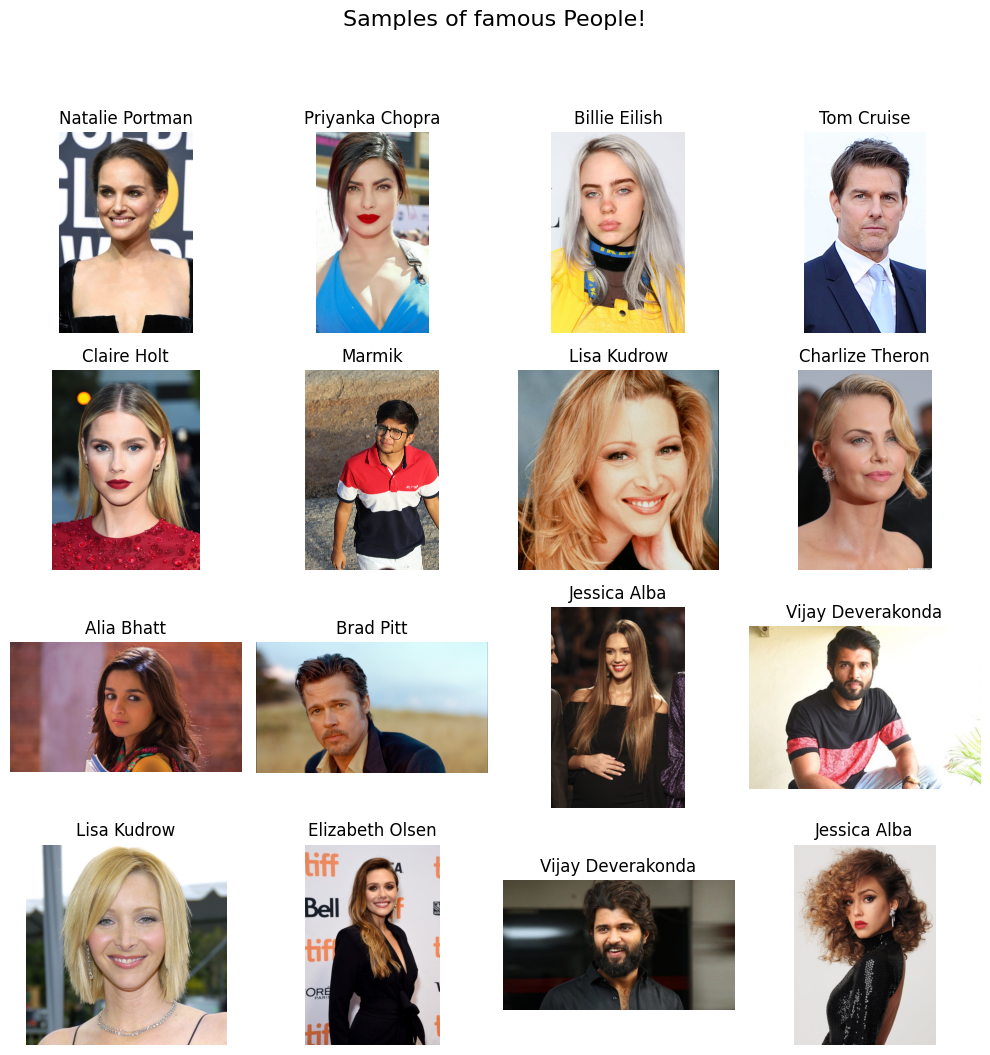

In [19]:
show_samples(images,labels)

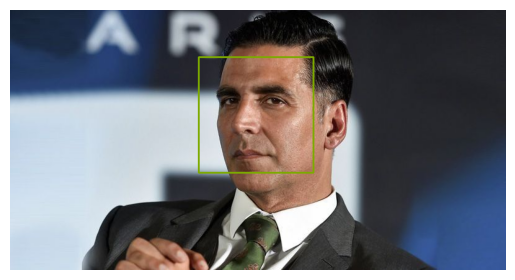

In [20]:
detect=face_recognition.load_image_file(images[10])
locations=face_recognition.face_locations(detect)
encode=face_recognition.face_encodings(detect,locations)

#image_cv = cv2.cvtColor(detect, cv2.COLOR_BGR2RGB)

#Draw bounding boxes around each face
for (top, right, bottom, left) in locations:
    cv2.rectangle(detect, (left, top), (right, bottom), (125, 170, 0), 2)

plt.imshow(detect)
plt.axis('off')  # Turn off axis labels
plt.show()

In [21]:
X=[]
y=[]
c=0
for subdir in os.listdir(dirpath):

  for imgpath in image_files_in_folder(os.path.join(dirpath,subdir)):
      img=face_recognition.load_image_file(imgpath)

      location=face_recognition.face_locations(img)
      # i just want images with one face for training
      if len(location)!=1:
        continue
      else:
        X.append(face_recognition.face_encodings(img,known_face_locations=location)[0])
        y.append(subdir)
print(len(X))
print(len(y))

2499
2499


In [22]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
model=KNeighborsClassifier(n_neighbors=2,weights='distance')
model.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=2, weights='distance')

In [24]:
y_pred=model.predict(x_test)
print(classification_report(y_test,y_pred))

                    precision    recall  f1-score   support

      Akshay Kumar       1.00      1.00      1.00        10
Alexandra Daddario       1.00      1.00      1.00        18
        Alia Bhatt       1.00      1.00      1.00        15
  Amitabh Bachchan       1.00      1.00      1.00        15
      Andy Samberg       1.00      1.00      1.00        18
    Anushka Sharma       1.00      1.00      1.00        13
     Billie Eilish       0.95      1.00      0.97        19
         Brad Pitt       1.00      1.00      1.00        24
    Camila Cabello       1.00      0.94      0.97        17
   Charlize Theron       1.00      1.00      1.00        16
       Claire Holt       1.00      1.00      1.00        19
      Courtney Cox       1.00      1.00      1.00        16
    Dwayne Johnson       1.00      1.00      1.00        12
   Elizabeth Olsen       1.00      1.00      1.00        14
   Ellen Degeneres       1.00      1.00      1.00        15
      Henry Cavill       1.00      1.00

c:\Python\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Python\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Python\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Python\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

<Figure size 800x600 with 0 Axes>

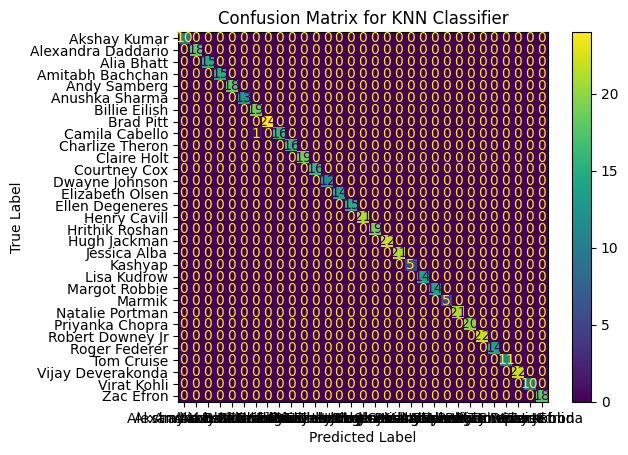

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assuming y_test and y_pred are defined
cm = confusion_matrix(y_test, y_pred)

# Get unique classes
unique_labels = np.unique(np.concatenate((y_test, y_pred)))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=unique_labels)
disp.plot()
plt.title("Confusion Matrix for KNN Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [40]:
# Assuming 'images' is a list of image file paths
index = np.random.randint(0, len(images))
test_image = face_recognition.load_image_file(images[index])
resized_image = cv2.resize(test_image, (500, 500))

# Get face locations and encodings
locations = face_recognition.face_locations(resized_image)
encodings = face_recognition.face_encodings(resized_image, locations)

# Check if any faces were found
if len(encodings) > 0:  # Ensure encodings are found
    # Convert to a 2D array for the model
    encodings = np.array(encodings)

    # Initialize the threshold for matching
    threshold = 0.6

    # Get closest distances
    distances = model.kneighbors(encodings, n_neighbors=1, return_distance=True)

    # Determine matches based on threshold
    all_matches = [distances[0][i][0] <= threshold for i in range(len(distances[0]))]

    # Go through all the face locations and predict names of the matched face
    for i in range(len(locations)):
        if all_matches[i]:
            name = model.predict([encodings[i]])[0]
        else:
            name = 'unknown'
        print(f"Face at location {locations[i]} is recognized as: {name}")
else:
    print("No faces found in the image.")

Face at location (98, 366, 284, 180) is recognized as: Amitabh Bachchan


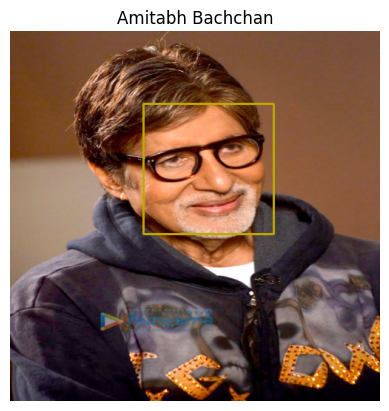

In [41]:
for (top, right, bottom, left) in locations:
    cv2.rectangle(resized_image, (left, top), (right-10, bottom-10), (190, 170, 0), 2)
    #cv2.putText(resized_image,name,(left,top-20),cv2.FONT_HERSHEY_SIMPLEX,1,(190,100,120),2)

plt.imshow(resized_image)
plt.title(name)
plt.axis('off')  # Turn off axis labels
plt.show()